# Audible Insights - Step 3: NLP, Clustering and Recommendation Models

In this notebook I:
1. Convert book text into numbers using **TF-IDF** (NLP)
2. Group similar books using **K-Means** and **DBSCAN** (clustering)
3. Build 3 recommendation models: **Content-Based**, **Clustering-Based** and **Hybrid**
4. Compare the models using **Precision, Recall and RMSE**
5. Answer the Medium and Scenario questions

### Import libraries

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import scipy.sparse

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

sns.set_style("whitegrid")

### Load the cleaned data

In [2]:
df = pd.read_csv("../data/cleaned_books.csv")
df["Genres"] = df["Genres"].fillna("")
df["Description"] = df["Description"].fillna("")
df["text"] = df["text"].fillna("")
print(df.shape)

(6063, 11)


## Part 1: NLP - TF-IDF

TF-IDF gives a high score to words that are important for one book but not common across all books.
I use the `text` column (book name + genres + description) and remove English stop words like "the" and "is".

In [3]:
tfidf = TfidfVectorizer(stop_words="english", max_features=5000, min_df=2)
tfidf_matrix = tfidf.fit_transform(df["text"])

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (6063, 5000)


In [4]:
# Example: top words for one book
book_index = 0
row = tfidf_matrix[book_index].toarray()[0]
words = tfidf.get_feature_names_out()
top_word_index = row.argsort()[::-1][:10]

print("Book:", df["Book Name"][book_index])
print("Top words:", [words[i] for i in top_word_index])

Book: "Don't You Know Who I Am?": How to Stay Sane in an Era of Narcissism, Entitlement, and Incivility
Top words: ['era', 'stay', 'don', 'know', 'हम', 'extra', 'expressed', 'expressions', 'extensive', 'external']


## Part 2: Clustering

### K-Means: find the best number of clusters

I try different values of k and check:
- **Inertia** (elbow method): lower is better
- **Silhouette score**: higher is better (range -1 to 1). I calculate it on a sample of 2000 books to save time

K-Means is run directly on the TF-IDF matrix. TF-IDF rows are already normalized, so this works like grouping by cosine similarity.

In [5]:
k_values = [5, 10, 15, 20, 25, 30, 35]
inertia_list = []
silhouette_list = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(tfidf_matrix)
    score = silhouette_score(tfidf_matrix, labels, metric="cosine", sample_size=2000, random_state=42)
    inertia_list.append(kmeans.inertia_)
    silhouette_list.append(score)
    print("k =", k, " inertia =", round(kmeans.inertia_), " silhouette =", round(score, 3))

k = 5  inertia = 5737  silhouette = 0.008
k = 10  inertia = 5674  silhouette = 0.012
k = 15  inertia = 5619  silhouette = 0.016
k = 20  inertia = 5560  silhouette = 0.021
k = 25  inertia = 5645  silhouette = -0.011
k = 30  inertia = 5493  silhouette = 0.023
k = 35  inertia = 5462  silhouette = 0.027


k = 10  inertia = 5665  silhouette = 0.012


k = 15  inertia = 5614  silhouette = 0.016


k = 20  inertia = 5565  silhouette = 0.02


k = 25  inertia = 5522  silhouette = 0.024


k = 30  inertia = 5484  silhouette = 0.026


k = 35  inertia = 5610  silhouette = -0.012


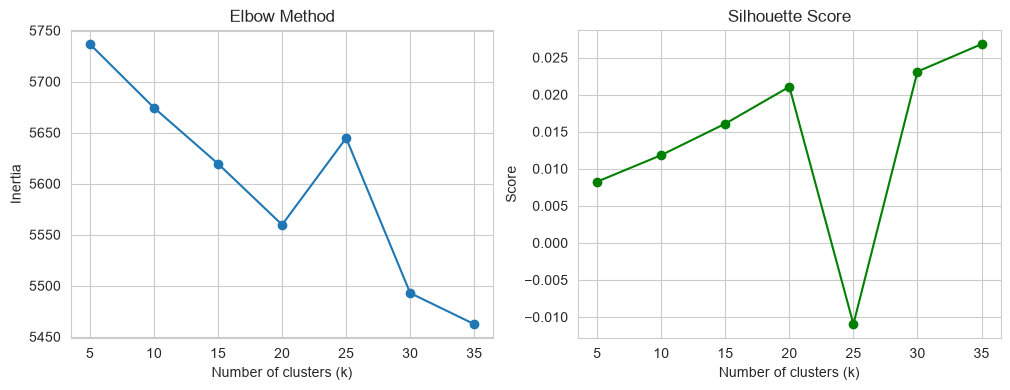

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(k_values, inertia_list, marker="o")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("Number of clusters (k)")
ax[0].set_ylabel("Inertia")

ax[1].plot(k_values, silhouette_list, marker="o", color="green")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("Number of clusters (k)")
ax[1].set_ylabel("Score")

plt.show()

**Observation:** there is no sharp elbow, and the silhouette scores are low. This is normal for text data because book topics overlap. The silhouette score rises up to k = 30 and then drops at k = 35.
I choose **k = 30** because it has the best silhouette score, and the clusters are still easy to understand.

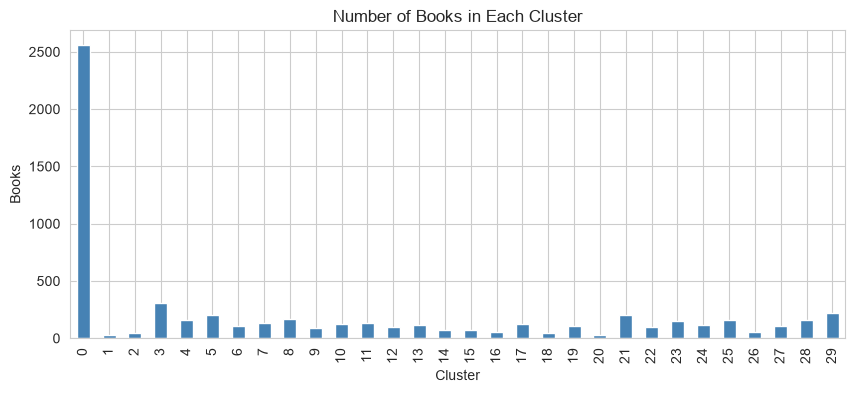

In [7]:
kmeans = KMeans(n_clusters=30, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(tfidf_matrix)

df["Cluster"].value_counts().sort_index().plot(kind="bar", figsize=(10, 4), color="steelblue")
plt.title("Number of Books in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Books")
plt.show()

### What is each cluster about?

One big cluster holds about 2,500 books. These are mostly books with only a short title and no description or genre, so K-Means can't separate them well.

In [8]:
cluster_words = []
for c in range(30):
    cluster_rows = tfidf_matrix[(df["Cluster"] == c).values]
    mean_scores = np.asarray(cluster_rows.mean(axis=0))[0]
    top = mean_scores.argsort()[::-1][:6]
    top_words = ", ".join([words[i] for i in top])
    cluster_words.append([c, (df["Cluster"] == c).sum(), top_words])

cluster_info = pd.DataFrame(cluster_words, columns=["Cluster", "Books", "Top Words"])
cluster_info

,Cluster,Books,Top Words
0,0,2560,"story, world, time, art, god, biographies"
1,1,26,"little, book, pigs, big, profits, stocks"
2,2,50,"money, make, financial, finance, attract, inside"
3,3,308,"book, series, tom, trilogy, gates, chronicles"
4,4,163,"personal, success, self, help, development, life"
5,5,205,"mind, power, body, spirit, meditation, healing"
6,6,111,"love, romance, tinder, story, contemporary, times"
7,7,135,"new, york, best, times, selling, science"
8,8,170,"history, world, india, war, indian, political"
9,9,88,"people, successful, psychology, highly, habits..."


### DBSCAN (for comparison)

DBSCAN finds the number of clusters by itself and marks books that don't fit any group as **noise (-1)**.

In [9]:
for eps in [0.6, 0.7, 0.8]:
    dbscan = DBSCAN(eps=eps, min_samples=5, metric="cosine")
    labels = dbscan.fit_predict(tfidf_matrix)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    print("eps =", eps, " clusters =", n_clusters, " noise books =", n_noise)

eps = 0.6  clusters = 55  noise books = 3325
eps = 0.7  clusters = 5  noise books = 1279
eps = 0.8  clusters = 1  noise books = 251


eps = 0.7  clusters = 5  noise books = 1293


eps = 0.8  clusters = 1  noise books = 250


**K-Means vs DBSCAN:**
- With small eps, DBSCAN marks many books as noise, and those books can't get cluster recommendations
- With large eps, almost everything merges into one big cluster
- Text data has no clear dense groups, so **DBSCAN doesn't work well here**
- **K-Means is chosen** because every book gets a cluster

## Part 3: Recommendation Models

First I create a **popularity score** for each book. From the EDA I learned that rating alone is not reliable when there are few reviews, so the score combines rating with the number of reviews.

In [10]:
df["Rating Filled"] = df["Rating"].fillna(df["Rating"].mean())

# log is used because reviews range from 0 to 70,000
df["Score"] = df["Rating Filled"] * np.log1p(df["Number of Reviews"])
df["Score"] = df["Score"] / df["Score"].max()     # scale to 0-1

df[["Book Name", "Rating", "Number of Reviews", "Score"]].sort_values(by="Score", ascending=False).head()

,Book Name,Rating,Number of Reviews,Score
4936,The Nightingale,4.8,40958,1.000000
4819,The Martian,4.7,33293,0.960064
4386,The Fault in Our Stars,4.5,43869,0.943561
581,Beneath a Scarlet Sky: A Novel,4.7,24240,0.930807
3907,The Alchemist: A Fable About Following Your Dream,4.6,28237,0.924774


### Helper function to find a book by name

In [11]:
def find_book(name):
    matches = df[df["Book Name"].str.lower().str.contains(name.lower(), regex=False)]
    if len(matches) == 0:
        return None
    # if there are many matches, take the most reviewed one
    return matches.sort_values(by="Number of Reviews", ascending=False).index[0]

find_book("atomic habits")

np.int64(478)

### Model 1: Content-Based Filtering

Find the books whose TF-IDF vectors are most similar (cosine similarity) to the selected book.

In [12]:
def content_recommend(book_index, n=5):
    similarity = cosine_similarity(tfidf_matrix[book_index], tfidf_matrix)[0]
    similarity[book_index] = -1                      # don't recommend the same book
    top_index = similarity.argsort()[::-1][:n]
    result = df.loc[top_index, ["Book Name", "Author", "Rating", "Primary Genre"]].copy()
    result["Similarity"] = similarity[top_index].round(3)
    return result

content_recommend(find_book("atomic habits"))

,Book Name,Author,Rating,Primary Genre,Similarity
1803,High Performance Habits: How Extraordinary Peo...,Brendon Burchard,4.6,Stress Management,0.455
1639,"Good Habits, Bad Habits: The Science of Making...",Wendy Wood,4.4,Unknown,0.435
818,"Change Your Habits, Change Your Life: Strategi...",Tom Corley,4.4,Money Management,0.345
2818,Nayi Aadton Ki Safal Takniken [Successful Tech...,Tejgyan Global Foundation,NaN,Unknown,0.288
3874,The 7 Habits Foundational Principles,FranklinCovey,NaN,Unknown,0.271


### Model 2: Clustering-Based

Recommend the best books (highest popularity score) from the **same cluster** as the selected book.

In [13]:
def cluster_recommend(book_index, n=5):
    cluster = df.loc[book_index, "Cluster"]
    same_cluster = df[(df["Cluster"] == cluster) & (df.index != book_index)]
    same_cluster = same_cluster.sort_values(by="Score", ascending=False)
    return same_cluster[["Book Name", "Author", "Rating", "Primary Genre", "Cluster"]].head(n)

cluster_recommend(find_book("atomic habits"))

,Book Name,Author,Rating,Primary Genre,Cluster
3316,Rich Dad Poor Dad: What the Rich Teach Their K...,Robert T. Kiyosaki,4.5,Personal Finance,4
1943,How to Win Friends and Influence People,Dale Carnegie,4.5,Communication & Social Skills,4
5337,The Subtle Art of Not Giving a F*ck: A Counter...,Mark Manson,4.4,Personal Success,4
4566,The Help,Kathryn Stockett,4.7,Unknown,4
5744,"Untamed: Stop Pleasing, Start Living",Glennon Doyle,4.7,Women Biographies,4


### Model 3: Hybrid

Combines both ideas:
- **70% content similarity** (the book must be about a similar topic)
- **20% popularity score** (prefer good, well-reviewed books)
- **10% bonus** if the book is in the same cluster

In [14]:
def hybrid_recommend(book_index, n=5):
    similarity = cosine_similarity(tfidf_matrix[book_index], tfidf_matrix)[0]
    same_cluster = (df["Cluster"] == df.loc[book_index, "Cluster"]).astype(int).values

    final_score = 0.7 * similarity + 0.2 * df["Score"].values + 0.1 * same_cluster
    final_score[book_index] = -1
    top_index = final_score.argsort()[::-1][:n]

    result = df.loc[top_index, ["Book Name", "Author", "Rating", "Primary Genre"]].copy()
    result["Hybrid Score"] = final_score[top_index].round(3)
    return result

hybrid_recommend(find_book("atomic habits"))

,Book Name,Author,Rating,Primary Genre,Hybrid Score
1803,High Performance Habits: How Extraordinary Peo...,Brendon Burchard,4.6,Stress Management,0.551
818,"Change Your Habits, Change Your Life: Strategi...",Tom Corley,4.4,Money Management,0.432
5633,Tiny Habits: The Small Changes That Change Eve...,BJ Fogg,4.6,Personal Success,0.391
1639,"Good Habits, Bad Habits: The Science of Making...",Wendy Wood,4.4,Unknown,0.389
1640,"Good Morning, Good Life: 5 Simple Habits to Ma...",Amy Schmittauer Landino,4.7,Time Management,0.385


## Part 4: Evaluation

**Problem:** the dataset has no user-level data (who read what), so we can't check against real user behaviour.

**My approach:**
- **Precision@10 / Recall@10:** a recommended book counts as **relevant** if it shares at least one genre with the selected book. I test on books that have genres.
  - Precision = relevant books recommended / 10
  - Recall = relevant books recommended / total relevant books in the dataset
- **RMSE:** I predict each book's rating as the average rating of its 10 recommended books, then compare with the actual rating. A good recommender suggests books of similar quality.

In [15]:
def get_top_n(model, book_index, n=10):
    if model == "content":
        similarity = cosine_similarity(tfidf_matrix[book_index], tfidf_matrix)[0]
        similarity[book_index] = -1
        return similarity.argsort()[::-1][:n]
    if model == "cluster":
        return cluster_recommend(book_index, n).index.values
    if model == "hybrid":
        return hybrid_recommend(book_index, n).index.values

genre_sets = [set(g.split("|")) if g != "" else set() for g in df["Genres"]]

# test books: books that have genres and a rating
test_books = df[(df["Genres"] != "") & (df["Rating"].notnull())].sample(300, random_state=42).index

In [16]:
def evaluate(model, n=10):
    precision_list = []
    recall_list = []
    actual = []
    predicted = []

    for i in test_books:
        recs = get_top_n(model, i, n)
        relevant = 0
        for r in recs:
            if len(genre_sets[i] & genre_sets[r]) > 0:
                relevant += 1

        total_relevant = sum(1 for j in range(len(df)) if j != i and len(genre_sets[i] & genre_sets[j]) > 0)
        precision_list.append(relevant / n)
        recall_list.append(relevant / total_relevant if total_relevant > 0 else 0)

        rec_ratings = df.loc[recs, "Rating"].dropna()
        if len(rec_ratings) > 0:
            actual.append(df.loc[i, "Rating"])
            predicted.append(rec_ratings.mean())

    rmse = np.sqrt(np.mean((np.array(actual) - np.array(predicted)) ** 2))
    return round(np.mean(precision_list), 3), round(np.mean(recall_list), 3), round(rmse, 3)

In [17]:
results = []
for model in ["content", "cluster", "hybrid"]:
    p, r, rmse = evaluate(model)
    results.append([model, p, r, rmse])
    print(model, "done")

# baseline: predict every book's rating as the overall average
baseline_rmse = np.sqrt(np.mean((df.loc[test_books, "Rating"] - df["Rating"].mean()) ** 2))
print("Baseline RMSE (always predict average):", round(baseline_rmse, 3))

results_df = pd.DataFrame(results, columns=["Model", "Precision@10", "Recall@10", "RMSE"])
results_df

content done
cluster done
hybrid done
Baseline RMSE (always predict average): 0.349


,Model,Precision@10,Recall@10,RMSE
0,content,0.393,0.120,0.345
1,cluster,0.238,0.030,0.360
2,hybrid,0.455,0.111,0.347


hybrid done
Baseline RMSE (always predict average): 0.349


,Model,Precision@10,Recall@10,RMSE
0,content,0.392,0.120,0.347
1,cluster,0.194,0.027,0.362
2,hybrid,0.434,0.109,0.347


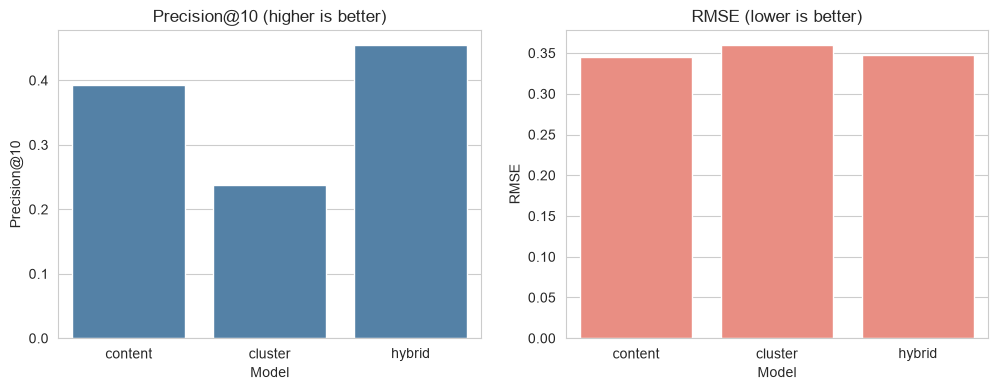

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x="Model", y="Precision@10", data=results_df, ax=ax[0], color="steelblue")
ax[0].set_title("Precision@10 (higher is better)")
sns.barplot(x="Model", y="RMSE", data=results_df, ax=ax[1], color="salmon")
ax[1].set_title("RMSE (lower is better)")
plt.show()

**Observation:**
- **Hybrid is the best model**, with the highest precision (about 0.43). Its RMSE (0.347) is the same as content-based
- **Content-based** is close behind (precision about 0.39) and has the best recall
- **Cluster-based** is the weakest (precision about 0.19) because some clusters are large and mixed. It only knows "same group", not "how similar"
- RMSE is close to the baseline for all models (about 0.35) because most books are rated 4.3 to 4.7, so predicting ratings is not very informative here. Precision is the more useful metric for this project
- Recall is low for all models because a genre like Personal Success has 200 books, and we only recommend 10

## Part 5: Medium Level Questions

### Q1. Which books are frequently clustered together based on descriptions?

In [19]:
for c in cluster_info.sort_values(by="Books")["Cluster"].values[:5]:
    print("Cluster", c, "-", cluster_info.loc[c, "Top Words"])
    print(df[df["Cluster"] == c].sort_values(by="Score", ascending=False)["Book Name"].head(5).str[:70].tolist())
    print()

Cluster 1 - little, book, pigs, big, profits, stocks
['Little Women', 'A Little Life', 'The Little Book of Hygge: The Danish Way to Live Well', 'Pawn of Prophecy: The Belgariad, Book 1', 'A Hundred Little Flames']

Cluster 20 - magic, tree, house, book, witchcraft, rainbow
['Big Magic: Creative Living Beyond Fear', 'Wicca Book of Spells: A Book of Shadows for Wiccans, Witches, and Othe', 'Dinosaurs Before Dark: Magic Tree House, Book 1', 'The Rules of Magic', 'Wicca for Beginners: A Guide to Wiccan Beliefs, Rituals, Magic, and Wi']

Cluster 18 - free, audible, interview, sessions, exclusive, stress
['Great Expectations: The Dickens Collection: An Audible Exclusive Serie', 'The Tapping Solution: A Revolutionary System for Stress-Free Living', 'Free to Focus: A Total Productivity System to Achieve More by Doing Le', 'The Mayo Clinic Guide to Stress-Free Living', 'Lies Women Believe: And the Truth That Sets Them Free']

Cluster 2 - money, make, financial, finance, attract, inside
['The 1-

### Q2. How does genre similarity affect recommendations?

In [20]:
# Compare text similarity for book pairs that share a genre vs pairs that don't
genre_books = df[df["Genres"] != ""].sample(500, random_state=1).index
sim = cosine_similarity(tfidf_matrix[genre_books])

same_genre = []
diff_genre = []
for a in range(len(genre_books)):
    for b in range(a + 1, len(genre_books)):
        if len(genre_sets[genre_books[a]] & genre_sets[genre_books[b]]) > 0:
            same_genre.append(sim[a, b])
        else:
            diff_genre.append(sim[a, b])

print("Average similarity - same genre     :", round(np.mean(same_genre), 3))
print("Average similarity - different genre:", round(np.mean(diff_genre), 3))

Average similarity - same genre     : 0.119
Average similarity - different genre: 0.015


**Observation:** books that share a genre are about **8 times more similar** in text (0.118 vs 0.015). So genre is a strong signal, and including genre words in the text helps the recommender find books of the same kind.

### Q3. What is the effect of author popularity on ratings?

                   count      mean       std
Popularity                                  
Low (0-50)           717  4.309297  0.564828
Medium (51-500)     1592  4.466613  0.258004
High (501-5000)     1064  4.516918  0.211440
Very High (5000+)    216  4.515929  0.170583


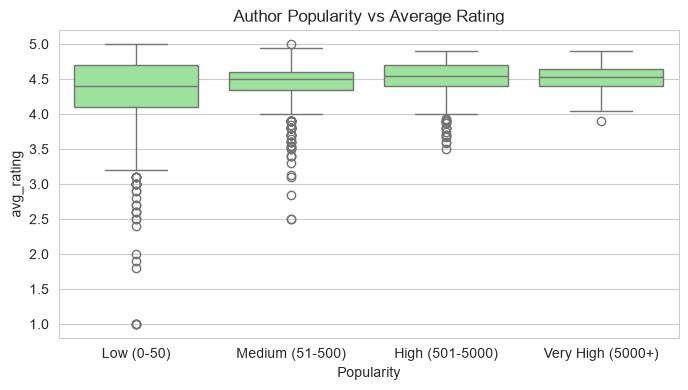

In [21]:
author_df = df[df["Rating"].notnull()].groupby("Author").agg(
    total_reviews=("Number of Reviews", "sum"),
    avg_rating=("Rating", "mean"),
    books=("Rating", "count")
)

author_df["Popularity"] = pd.cut(author_df["total_reviews"], bins=[-1, 50, 500, 5000, 1000000],
                                 labels=["Low (0-50)", "Medium (51-500)", "High (501-5000)", "Very High (5000+)"])
print(author_df.groupby("Popularity", observed=True)["avg_rating"].agg(["count", "mean", "std"]))

plt.figure(figsize=(8, 4))
sns.boxplot(x="Popularity", y="avg_rating", data=author_df, color="lightgreen")
plt.title("Author Popularity vs Average Rating")
plt.show()

**Observation:** authors with very few reviews have lower and more varied ratings (4.31, with a high std). Popular authors have slightly higher and much more consistent ratings (about 4.52). So popularity makes ratings more **reliable**, but it doesn't raise them much above 4.5.

### Q4. Which combination of features gives the most accurate recommendations?

I build TF-IDF using different text columns and compare Precision@10 (content-based model).

In [22]:
feature_options = {
    "Title only": df["Book Name"],
    "Title + Description": df["Book Name"] + " " + df["Description"],
    "Title + Genres": df["Book Name"] + " " + df["Genres"].str.replace("|", " "),
    "Title + Genres + Description": df["text"],
}

feature_results = []
for name, text in feature_options.items():
    matrix = TfidfVectorizer(stop_words="english", max_features=5000, min_df=2).fit_transform(text)
    precision_list = []
    for i in test_books:
        similarity = cosine_similarity(matrix[i], matrix)[0]
        similarity[i] = -1
        recs = similarity.argsort()[::-1][:10]
        relevant = sum(1 for r in recs if len(genre_sets[i] & genre_sets[r]) > 0)
        precision_list.append(relevant / 10)
    feature_results.append([name, round(np.mean(precision_list), 3)])

pd.DataFrame(feature_results, columns=["Features", "Precision@10"])

,Features,Precision@10
0,Title only,0.070
1,Title + Description,0.068
2,Title + Genres,0.701
3,Title + Genres + Description,0.393


**Observation:**
- Title only and Title + Description score low (about 0.07). Titles are short, and 60% of books have no real description
- **Genres are the most useful feature.** Title + Genres gives the highest precision (0.70)
- Note: relevance is also measured using genres, so the genre-based features have an advantage in this test
- I keep **Title + Genres + Description** in the final model because descriptions help find books about the same *topic* (for example, habit books for "Atomic Habits"), which genre alone can't do

## Part 6: Scenario Based Questions

### S1. A new user likes Science Fiction. Which top 5 books should be recommended?

A new user has no history, so I recommend the best books (popularity score) from the genre.

In [23]:
def recommend_by_genre(genre, n=5):
    books = df[df["Genres"].str.contains(genre, case=False, regex=False)]
    books = books.sort_values(by="Score", ascending=False)
    return books[["Book Name", "Author", "Rating", "Number of Reviews"]].head(n)

recommend_by_genre("Science Fiction")

,Book Name,Author,Rating,Number of Reviews
4819,The Martian,Andy Weir,4.7,33293
3241,Ready Player One,Ernest Cline,4.6,17237
2699,"Mockingjay: The Hunger Games, Book 3",Suzanne Collins,4.5,18723
43,1984,George Orwell,4.5,17140
5383,The Testaments,Margaret Atwood,4.6,10693


### S2. A user rated thrillers highly. Recommend similar books.

I take the user's highly rated thrillers, average their TF-IDF vectors (a "user profile"), and find similar books.

In [24]:
thrillers = df[df["Primary Genre"].str.contains("Thriller", case=False) & (df["Rating"] >= 4.5)]
user_books = thrillers.sort_values(by="Number of Reviews", ascending=False).head(3).index
print("User liked:")
print(df.loc[user_books, "Book Name"].tolist())

user_profile = np.asarray(tfidf_matrix[user_books].mean(axis=0))
similarity = cosine_similarity(user_profile, tfidf_matrix)[0]
final_score = 0.8 * similarity + 0.2 * df["Score"].values
final_score[user_books] = -1

top = final_score.argsort()[::-1][:5]
df.loc[top, ["Book Name", "Author", "Rating", "Primary Genre"]]

User liked:
['Then She Was Gone', 'Tripwire: Jack Reacher, Book 3', 'The Family Upstairs']


,Book Name,Author,Rating,Primary Genre
2244,"Killing Floor: Jack Reacher, Book 1",Lee Child,4.4,Crime Thrillers
2983,Origin: Robert Langdon 5,Dan Brown,4.3,Conspiracy Thrillers
4474,The Girl in Room 105,Chetan Bhagat,4.3,Psychological Thrillers
2737,Mumbai Avengers,S. Hussain Zaidi,3.8,Espionage Thrillers
3255,Rebecca,Daphne Du Maurier,4.5,Suspense


### S3. Hidden gems: highly rated but low popularity

In [25]:
hidden_gems = df[(df["Rating"] >= 4.7) & (df["Number of Reviews"] >= 5) & (df["Number of Reviews"] <= 50)]
hidden_gems = hidden_gems.sort_values(by=["Rating", "Number of Reviews"], ascending=False)
print("Hidden gems found:", len(hidden_gems))
hidden_gems[["Book Name", "Author", "Rating", "Number of Reviews", "Primary Genre"]].head(10)

Hidden gems found: 217


,Book Name,Author,Rating,Number of Reviews,Primary Genre
3235,"Raven’s Hart: Haven Hart Series, Book 7",Davidson King,5.0,37,Unknown
4414,The Fish Who Found the Sea,Alan Watts,5.0,30,Unknown
3695,Stop Making Sense: The Art of Inspiring Anybody,Michael J. Fanuele,5.0,28,Unknown
4060,The Book of Esports: The Definitive Guide to C...,William Collis,5.0,25,Unknown
4825,The Master Key System Audiobook - All 28 Parts,Charles F. Haanel,5.0,21,Unknown
1300,"Energy Healing for Trauma, Stress & Chronic Il...",Cyndi Dale,5.0,17,Chakras
2794,Naked and Unafraid: 5 Keys to Abandon Smallnes...,Kevin Gerald,5.0,17,Unknown
910,Coming Home to Yourself: A Meditator's Guide t...,Osho,5.0,16,Meditation
1533,From a Mountain in Tibet: A Monk’s Journey,Lama Yeshe Losal Rinpoche,5.0,15,Unknown
1155,Discover Your True North: Expanded and Updated...,Bill George,5.0,14,Leadership


I require at least 5 reviews, because a 5.0 rating from 1 review is not reliable (seen in the EDA).

## Part 7: Save the models for the Streamlit app

In [26]:
os.makedirs("../models", exist_ok=True)

joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")
joblib.dump(kmeans, "../models/kmeans_model.pkl")
scipy.sparse.save_npz("../models/tfidf_matrix.npz", tfidf_matrix)

df.drop(columns=["text"]).to_csv("../data/books_with_clusters.csv", index=False)
print("Models and data saved")

Models and data saved


## Summary

| Step | What I did |
|---|---|
| NLP | TF-IDF on title + genres + description (5000 words) |
| Clustering | K-Means with k = 30 (chosen using the elbow and silhouette scores). DBSCAN tested but not chosen because of too much noise |
| Models | Content-based (cosine similarity), Cluster-based (best books in the same cluster), Hybrid (70% similarity + 20% popularity + 10% same cluster) |
| Evaluation | Hybrid is best: Precision@10 = 0.43, RMSE = 0.347 |
| Saved | TF-IDF vectorizer, TF-IDF matrix, K-Means model, books_with_clusters.csv |